# 16 六例镜像扩展：统一ROI与强度处理技术试验

用户已批准本阶段。固定6名不同源患者，3次治疗改变、3次肿瘤，仅作技术试验。协议`reports/ucsd_roi_pilot_protocol.md`；运行后因FLAIR裁切损失增加的工程修正单独记录于`reports/ucsd_roi_pilot_intensity_amendment.md`，不追写为预设方案。

In [1]:
from pathlib import Path
import sys,json,runpy
import numpy as np
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from rn_public.ucsd_roi_pilot import run,SAMPLE_IDS
s=run(ROOT)
base=ROOT/'reports/ucsd_roi_pilot'
print(json.dumps(s,indent=2))
assert s['source_files_available']==s['source_files_decoded']==36
assert s['source_units_unknown']==36 and s['source_physical_QC_pass']==0

{
  "checked_at_utc": "2026-10-29T07:23:45.331007+00:00",
  "sample_cases": 6,
  "source_patients": 6,
  "source_files_requested": 36,
  "source_files_available": 36,
  "source_bytes_available": 43455955,
  "source_files_decoded": 36,
  "source_relative_grid_matches": 36,
  "source_physical_QC_pass": 0,
  "source_units_unknown": 36,
  "source_uint8_intensity_files": 30,
  "ROI_processing_success": 6,
  "structural_normalizations_success": 24,
  "histogram_success": 24,
  "erosion_histogram_success": 24,
  "normalization_parameters_fitted_across_patients": false,
  "normalization_parameters_use_ROI": false,
  "ROI_rule_uses_class": false,
  "source_annotation_blinding_confirmed": false,
  "pure_tumor_ROI": false,
  "physical_units_confirmed": false,
  "anatomical_alignment_accepted": false,
  "clinical_model_refitted": false,
  "MRI_model_fitted": false,
  "MRI_performance_estimated": false,
  "whole_cohort_downloaded": false,
  "next_step_requires_user_approval": true,
  "protocol_sha2

## 同一源标注区域并集

每例只合并普通BraTS所有正整数标签，保留全部连通区域，不按类别修改规则。不声称纯肿瘤组织或独立盲法。一次6邻域腐蚀仅为边界敏感性诊断，单位为体素。

In [2]:
cases=pd.read_csv(base/'case_ROI_diagnostics.csv')
qc=pd.read_csv(base/'source_file_QC.csv')
display(cases[['ID','tumor_label','roi_voxels','components_26','erosion_voxels','erosion_retention','success']])
assert len(cases)==cases.patient_id.nunique()==6
assert cases.tumor_label.value_counts().to_dict()=={0:3,1:3}
assert cases.success.all() and cases.roi_nonempty.all()
assert qc.relative_grid_status.eq('native_matrix_match').all()
assert not cases.physical_volume_computed.any()

,ID,tumor_label,roi_voxels,components_26,erosion_voxels,erosion_retention,success
0,UCSD-PTGBM-0002_01,0,111914,1,95270,0.851279,True
1,UCSD-PTGBM-0005_01,1,6587,1,4214,0.639745,True
2,UCSD-PTGBM-0006_01,1,92360,1,76978,0.833456,True
3,UCSD-PTGBM-0007_01,1,58013,5,46511,0.801734,True
4,UCSD-PTGBM-0008_02,0,22183,1,17185,0.774692,True
5,UCSD-PTGBM-0010_01,0,17882,3,13542,0.757298,True


## 初始裁切方案及执行后追加的不裁切修正

预设按每图非零支持区p1/p99缩放并裁切，所有24份结构图均成功。但ROI上端裁切最高约26%，因此保留初始结果并追加同参数不裁切线性缩放。该工程选择不使用类别或模型效果，不能称预先注册或最优。32箱用于技术诊断，不报告分类显著性。

In [3]:
from rn_public.ucsd_intensity_followup import run as followup
choice=followup(ROOT)
original=pd.read_csv(base/'normalization_diagnostics.csv')
revised=pd.read_csv(base/'unclipped_normalization_diagnostics.csv')
display(original[['ID','sequence','clipped_high_fraction','erosion_JS_distance']])
display(revised[['ID','sequence','normalized_minimum','normalized_maximum','occupied_bins','erosion_JS_distance']])
assert len(original)==len(revised)==24
assert revised.success.all() and choice['added_after_observing_clipping']
assert not choice['uses_clinical_class'] and not choice['model_performance_used']
print(json.dumps(choice,indent=2))

{
  "recommended_next_stage_method": "per_image_p01_p99_affine_unclipped_then_ROI_FBN32",
  "added_after_observing_clipping": true,
  "uses_clinical_class": false,
  "model_performance_used": false,
  "reason": "Avoid additional tail collapse measured under the original clipping rule",
  "original_clipping_outputs_preserved": true,
  "structural_records": 24,
  "successful_records": 24,
  "quantitative_ADC_allowed": false,
  "physical_volume_allowed": false,
  "independent_optimality_validated": false,
  "amendment_sha256": "f6917cdfac7ab2bd50cbb0eb3fbe0c5bd096808f284595d0099a4f3503246a60",
  "code_sha256": "670290f35c2e5b79dc1de254b21fd0cc4a200b935ae0d2eb7779c3e3bf1b5774"
}


,ID,sequence,clipped_high_fraction,erosion_JS_distance
0,UCSD-PTGBM-0002_01,FLAIR,0.129573,0.118192
1,UCSD-PTGBM-0002_01,T1pre,0.000063,0.070522
2,UCSD-PTGBM-0002_01,T1post,0.000000,0.056030
3,UCSD-PTGBM-0002_01,T2,0.040245,0.140883
4,UCSD-PTGBM-0005_01,FLAIR,0.243206,0.186081
5,UCSD-PTGBM-0005_01,T1pre,0.000455,0.140571
6,UCSD-PTGBM-0005_01,T1post,0.000152,0.149505
7,UCSD-PTGBM-0005_01,T2,0.090329,0.220056
8,UCSD-PTGBM-0006_01,FLAIR,0.152295,0.113777
9,UCSD-PTGBM-0006_01,T1pre,0.000130,0.081440


,ID,sequence,normalized_minimum,normalized_maximum,occupied_bins,erosion_JS_distance
0,UCSD-PTGBM-0002_01,FLAIR,0.065116,1.125581,32,0.117971
1,UCSD-PTGBM-0002_01,T1pre,-0.020134,1.234899,31,0.070309
2,UCSD-PTGBM-0002_01,T1post,-0.085106,1.000000,32,0.056058
3,UCSD-PTGBM-0002_01,T2,-0.081967,1.158470,31,0.140520
4,UCSD-PTGBM-0005_01,FLAIR,0.004717,1.165094,31,0.185517
5,UCSD-PTGBM-0005_01,T1pre,-0.034483,1.082759,32,0.142020
6,UCSD-PTGBM-0005_01,T1post,-0.050633,1.031646,30,0.149261
7,UCSD-PTGBM-0005_01,T2,0.129213,1.117978,32,0.218421
8,UCSD-PTGBM-0006_01,FLAIR,0.043269,1.187500,32,0.113611
9,UCSD-PTGBM-0006_01,T1pre,0.033113,1.059603,32,0.081693


## 实际源影像与派生ROI审阅图

选取ROI最大横断面，仅用于技术显示，三维处理使用全部区域。蓝色为全部源标注并集、橙色为一次腐蚀；图像对比度仅作显示。两套直方图分别保留。

Saved actual six-case ROI review and histogram figures


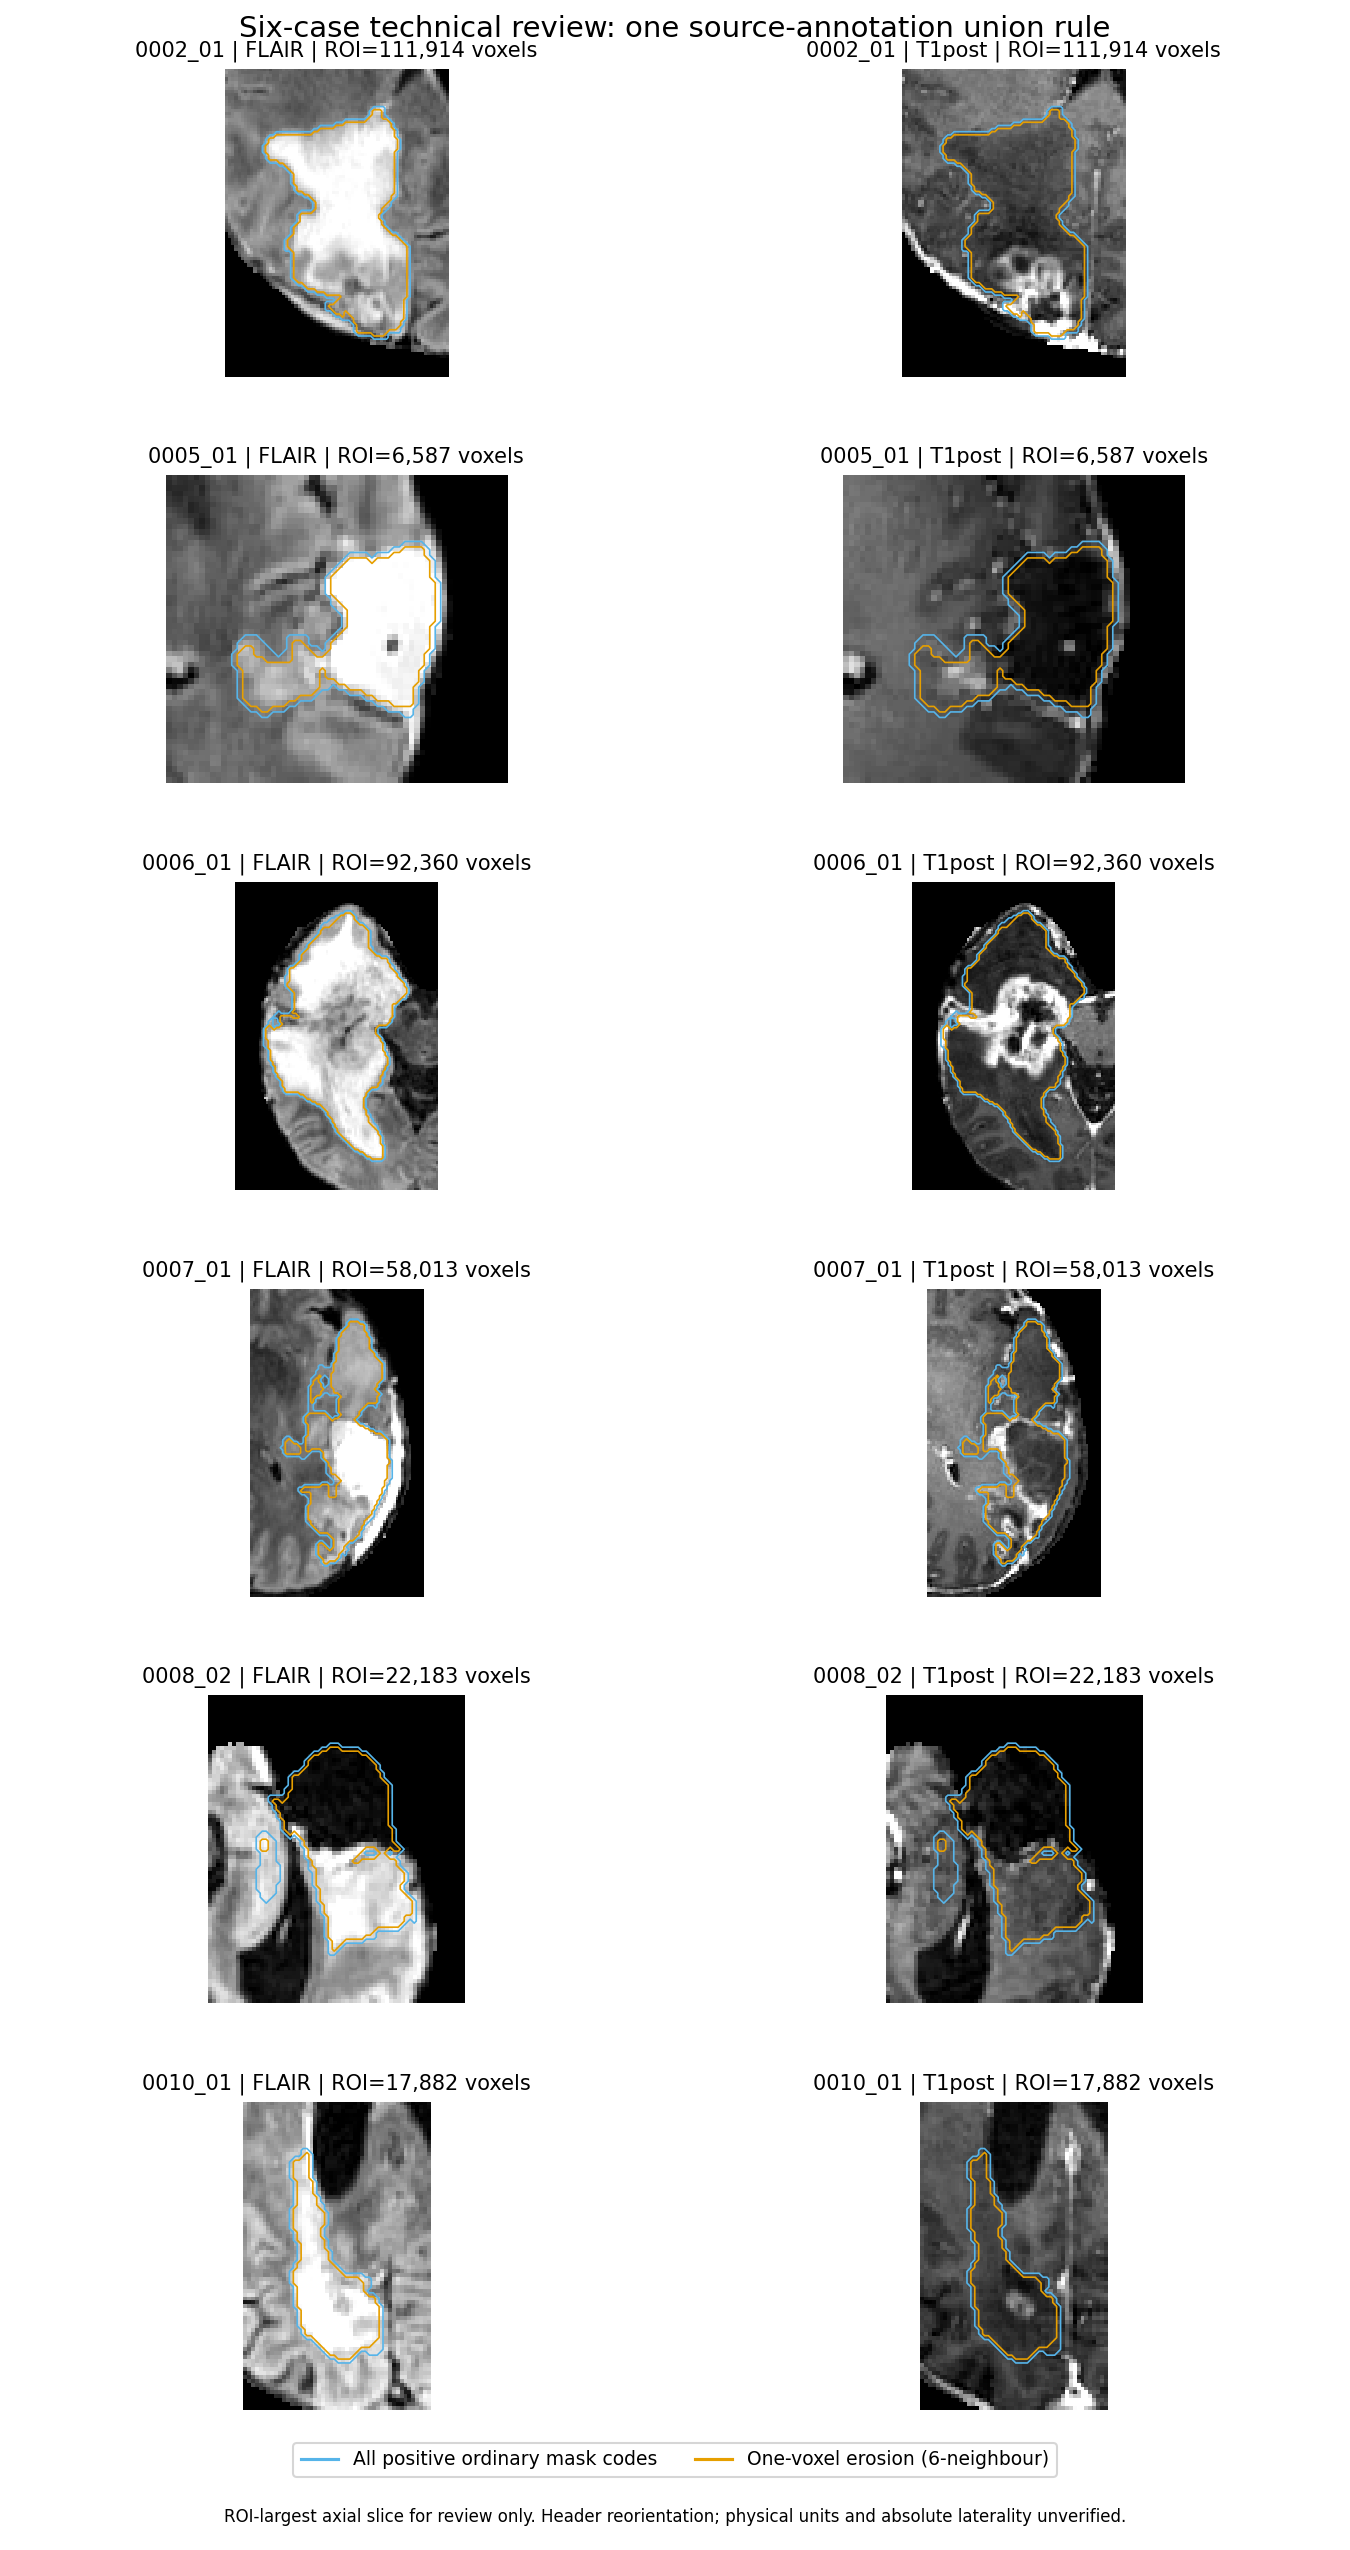

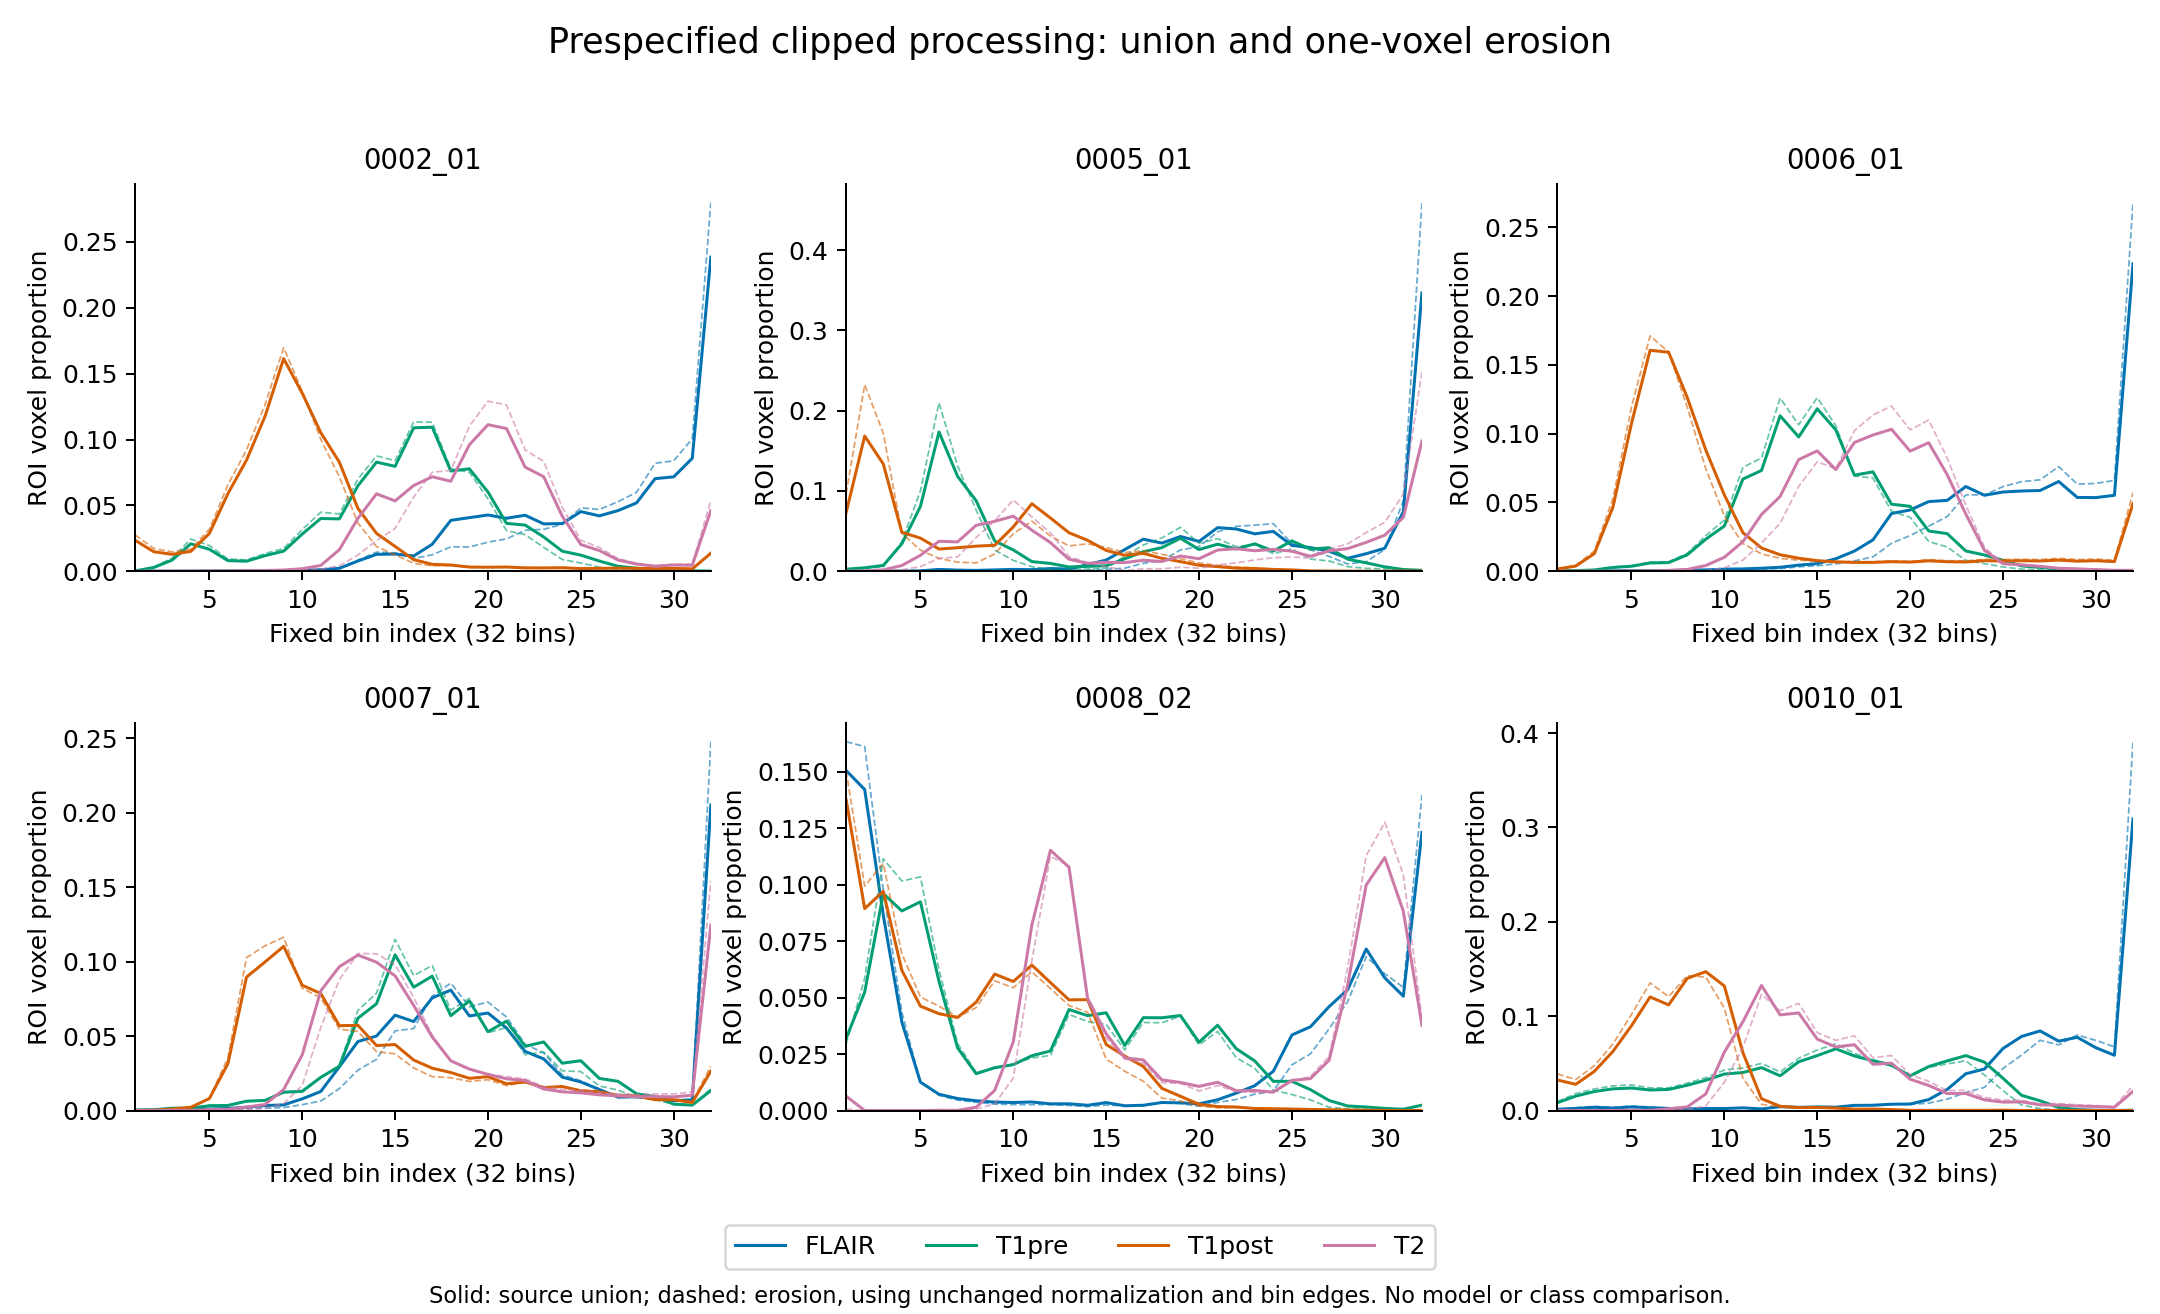

In [4]:
runpy.run_path(str(ROOT/'scripts/plot_ucsd_roi_pilot.py'),run_name='__main__')
for name in ['six_case_ROI_review.png','six_case_intensity_histograms.png','six_case_unclipped_histograms.png']:
    display(Image(filename=str(ROOT/'outputs/ucsd-roi-pilot-20261029'/name)))

## 解释边界及下一阶段

两组同规则技术处理成功，不等于独立临床验证。空间单位、原始定量ADC及源标注盲法仍未确认。下一阶段若获批，可按固定ROI和不裁切方案提取有限的探索性特征，并在共同病例上保留临床对照；本步没有模型或AUC。

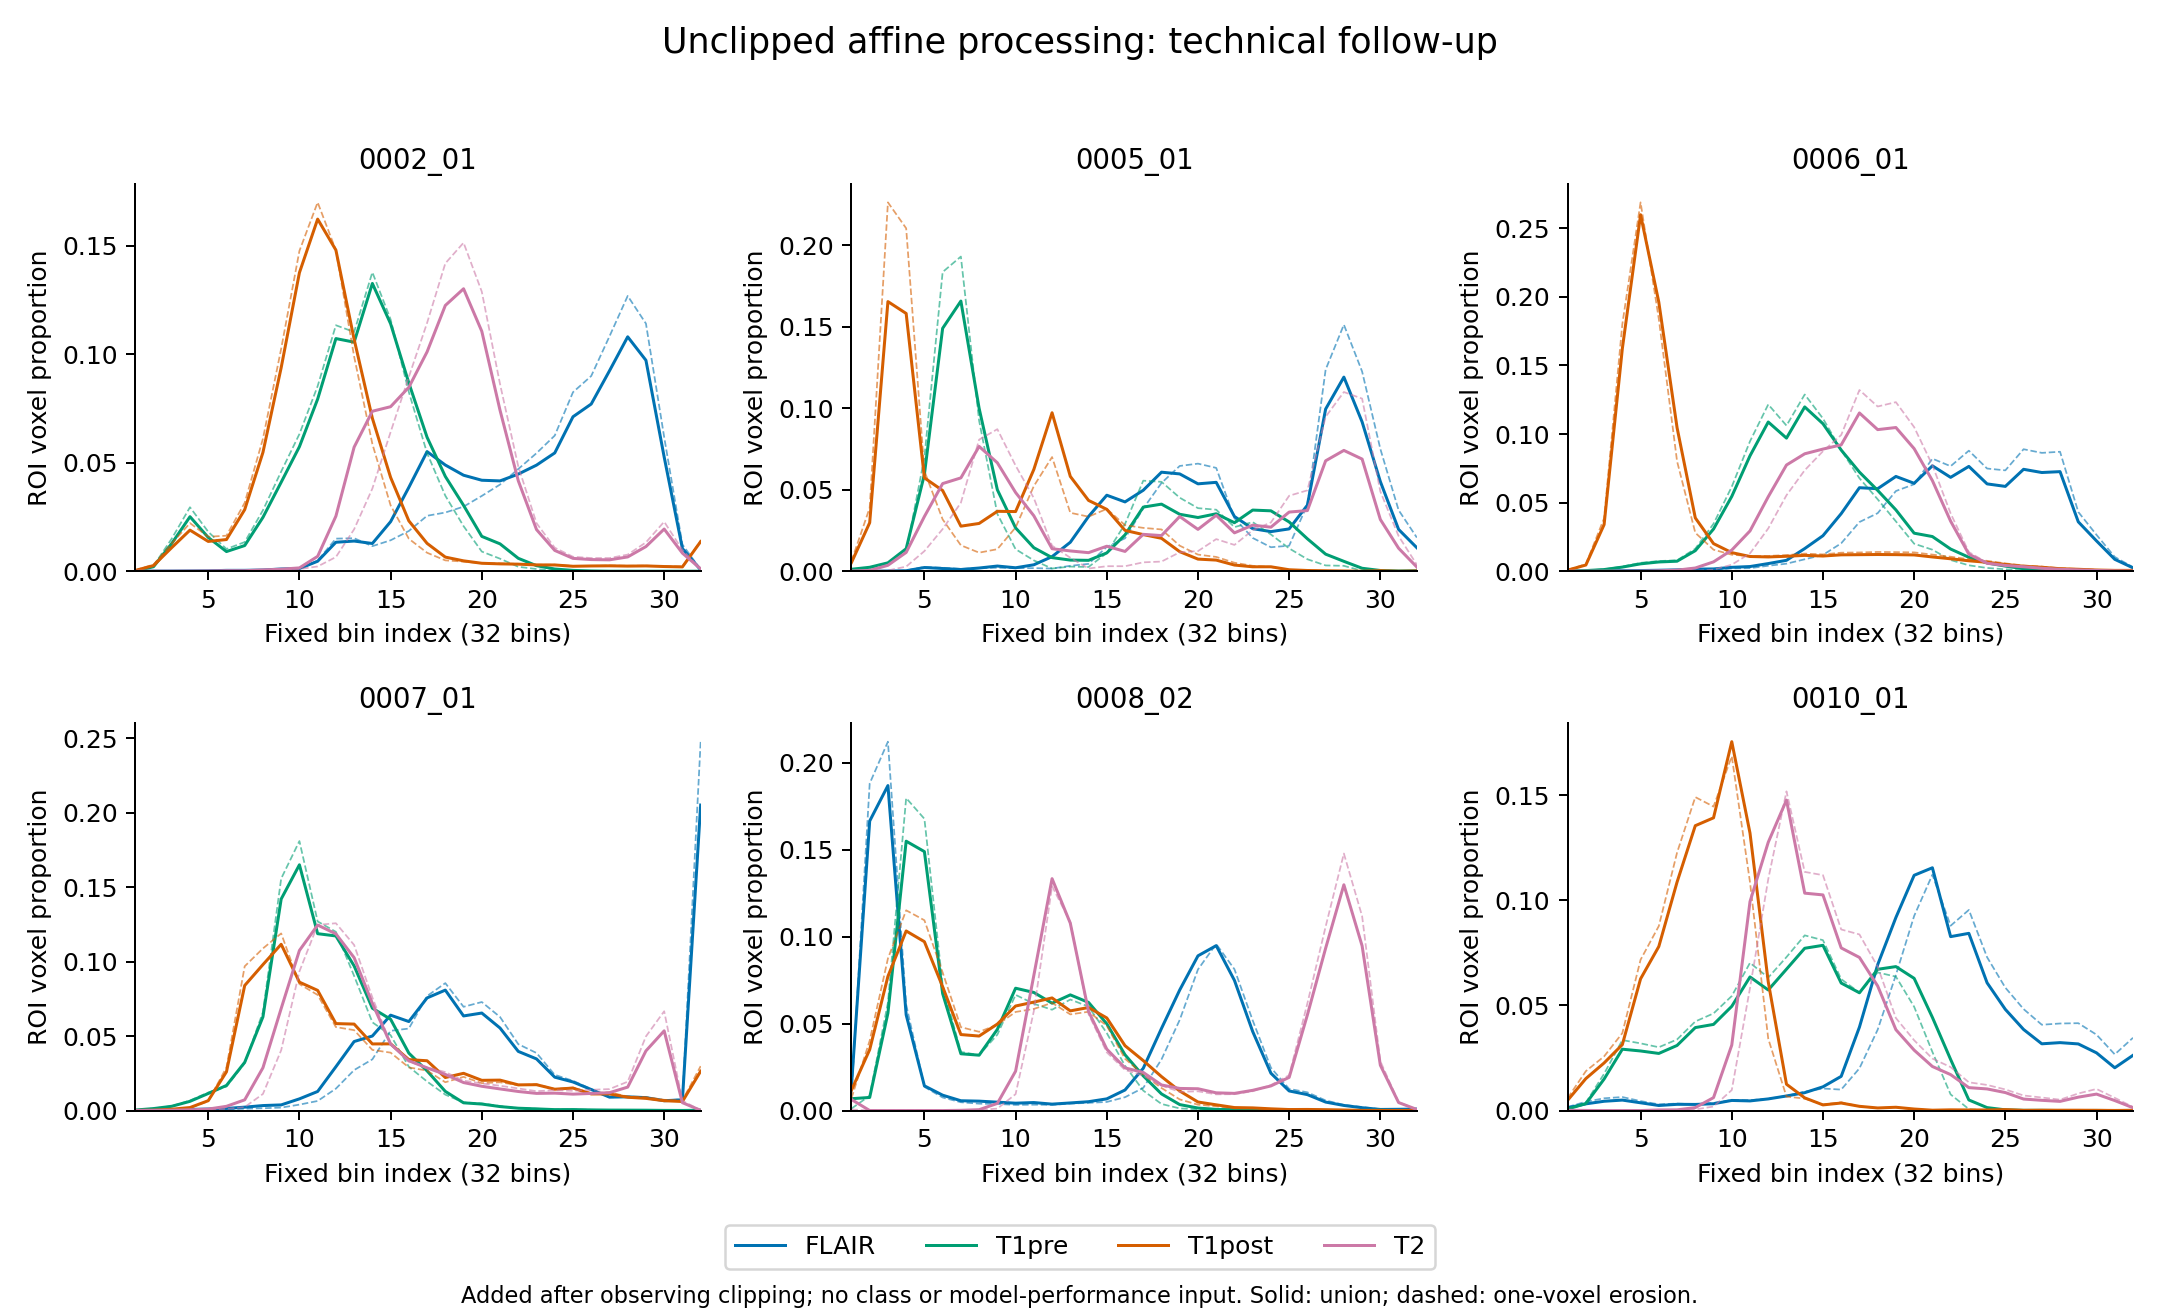

{
  "checked_at_utc": "2026-10-29T07:21:32.967864+00:00",
  "tests_run": 67,
  "failures": 0,
  "errors": 0,
  "skipped": 0,
  "success": true,
  "elapsed_seconds": 3.855,
  "new_ROI_pilot_tests": 6,
  "synthetic_array_tests_are_not_patient_data": true
}
Six-case technical pilot complete. Await next-stage approval.


In [5]:
tests=json.loads((base/'software_test_receipt.json').read_text())
print(json.dumps(tests,indent=2))
assert tests['success'] and tests['tests_run']==67
assert not s['MRI_model_fitted'] and not s['MRI_performance_estimated']
assert not s['clinical_model_refitted'] and not s['whole_cohort_downloaded']
assert s['next_step_requires_user_approval']
print('Six-case technical pilot complete. Await next-stage approval.')